# 06 · What survives contact with real music

Every number in notebooks 00–05 was measured against data I generated. That was a
deliberate choice — it let the methods be tested without waiting on credentials, and it
gave notebook 02 a ground truth that real users never come with — but it left one
question open the whole way through:

> **How much of this is a property of music, and how much is a property of my
> generator?**

The catalog is now real: **586,672 Spotify tracks** from the 2021 Kaggle dump, all
thirteen audio features, no nulls, 1900–2021, 3,629 distinct genres. This notebook
re-tests each earlier claim against it and marks the verdict.

One thing is still synthetic — **users**. Spotify's development mode caps the app at 25
allowlisted accounts, so there are no real listening histories to test against. Claims
that depend on how *people* listen stay open; claims about the catalog, the arithmetic,
and the features can now be settled.

In [1]:
import sys, warnings, time
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lovify_ml import schema as S, data, synthetic as syn, features as F, recommend as R, viz

pd.set_option("display.width", 180, "display.max_columns", 40)

real = data.load_catalog()
real = real.reset_index(drop=True)
print(f"\n{len(real):,} tracks  ·  {real[S.GENRE].nunique():,} distinct genres")
print(f"years {int(real[S.YEAR].min())}-{int(real[S.YEAR].max())}  ·  "
      f"nulls in audio features: {int(real[S.AUDIO_FEATURES].isna().sum().sum())}")

[data] REAL catalog: 586,672 tracks from tracks.csv

586,672 tracks  ·  3,629 distinct genres
years 1900-2021  ·  nulls in audio features: 0


## Claim 1 — the scaling bug

Notebook 00 measured `duration_ms` carrying over 99.99% of raw-column variance, and
notebook 03 found that this makes cosine similarity degenerate. This is arithmetic
rather than a property of the data, so it should hold. The point of re-measuring is
that real numbers are better evidence than synthetic ones.

In [2]:
var = real[S.AUDIO_FEATURES].var()
share = (var / var.sum()).sort_values(ascending=False)
print("share of total variance carried by each raw column:")
for f, v in share.items():
    print(f"  {f:<18} {v*100:>16.10f} %")
print(f"\nduration_ms alone               : {share['duration_ms']*100:.8f} %")
print(f"all 7 bounded features combined : {share[S.BOUNDED_FEATURES].sum()*100:.10f} %")
print(f"ratio                           : "
      f"{share['duration_ms']/share[S.BOUNDED_FEATURES].sum():,.0f} : 1")

share of total variance carried by each raw column:
  duration_ms           99.9999943018 %
  tempo                  0.0000055338 %
  loudness               0.0000001618 %
  acousticness           0.0000000008 %
  instrumentalness       0.0000000004 %
  valence                0.0000000004 %
  energy                 0.0000000004 %
  liveness               0.0000000002 %
  speechiness            0.0000000002 %
  danceability           0.0000000002 %

duration_ms alone               : 99.99999430 %
all 7 bounded features combined : 0.0000000026 %
ratio                           : 38,418,867,486 : 1


**Thirty-eight billion to one.** On synthetic data the ratio was large; on real
music it is larger still, because real durations range from seconds to hours while
synthetic ones were drawn from a tidy normal.

Now the consequence. If the vector norm is essentially `duration_ms`, then every song
points in nearly the same direction, and cosine — which measures only direction —
cannot tell them apart.

In [3]:
sub = real.sample(min(60_000, len(real)), random_state=0).reset_index(drop=True)   # random, not by popularity
raw = R.Recommender(sub, scale_features=False)

X = sub[S.AUDIO_FEATURES].to_numpy(float)
norms = np.linalg.norm(X, axis=1)
print(f"corr(||v||, duration_ms) = {np.corrcoef(norms, sub['duration_ms'])[0,1]:.10f}")

rng = np.random.default_rng(0)
q = X[rng.choice(len(X), 150, replace=False)].mean(0)
s = raw.Xn @ (q / np.linalg.norm(q))

print(f"\nscores across the catalog:")
print(f"  min {s.min():.10f}   max {s.max():.10f}")
print(f"  full dynamic range          {s.max()-s.min():.3e}")
print(f"  share scoring > 0.999999    {(s>0.999999).mean():.2%}")
print(f"  gap between 1st and 10th    {np.sort(s)[::-1][0]-np.sort(s)[::-1][9]:.3e}")

top = np.argsort(s)[::-1][:10]
print(f"\ntop-10 durations (minutes): "
      f"{[round(d/60000, 2) for d in sub['duration_ms'].iloc[top]]}")
print(f"catalog median duration   : {sub['duration_ms'].median()/60000:.2f} min")

corr(||v||, duration_ms) = 1.0000000000

scores across the catalog:
  min 0.9999688178   max 1.0000000000
  full dynamic range          3.118e-05
  share scoring > 0.999999    98.68%
  gap between 1st and 10th    1.316e-12

top-10 durations (minutes): [3.95, 3.87, 3.9, 3.98, 3.65, 3.82, 3.51, 3.88, 3.35, 3.68]
catalog median duration   : 3.58 min


The top ten are separated in the **twelfth decimal place**, and every one of
them is between 3.3 and 4.0 minutes against a catalog median of 3.6. The "most similar
songs" are songs of about the same length.

**Verdict: holds, and more strongly than on synthetic data.**

## Claim 2 — does the recommender still work?

Notebook 03 ran an ablation — raw cosine → scaling → taste modes → MMR → popularity
penalty — and scored it with recall@20 against a holdout. Re-running that here produces
something instructive.

In [4]:
listens, _ = syn.make_users(real, n_users=25, tracks_per_user=150, seed=23)
print(f"{listens[S.USER_ID].nunique()} synthetic users drawn from the REAL catalog, "
      f"{len(listens):,} (user, track) rows")

cfgs = [("raw cosine, mean vector (deck)", dict(scale=False, modes=1, pp=0.0, mmr=1.0)),
        ("+ scaling",                      dict(scale=True,  modes=1, pp=0.0, mmr=1.0)),
        ("+ 3 taste modes",                dict(scale=True,  modes=3, pp=0.0, mmr=1.0)),
        ("+ MMR 0.7",                      dict(scale=True,  modes=3, pp=0.0, mmr=0.7)),
        ("+ popularity penalty 0.15",      dict(scale=True,  modes=3, pp=0.15, mmr=0.7))]

rows = []
for name, c in cfgs:
    rec = R.Recommender(real, scale_features=c["scale"])
    m = R.holdout_evaluation(rec, listens, n=20, modes=c["modes"],
                             popularity_penalty=c["pp"], mmr_lambda=c["mmr"], seed=0)
    m["config"] = name
    rows.append(m)

abl = pd.DataFrame(rows)
abl[["config", "recall@20", "hit_rate@20", "intra_list_diversity",
     "mean_rec_popularity"]].round(4)

25 synthetic users drawn from the REAL catalog, 2,689 (user, track) rows


,config,recall@20,hit_rate@20,intra_list_diversity,mean_rec_popularity
0,"raw cosine, mean vector (deck)",0.0,0.0,0.0000,27.492
1,+ scaling,0.0,0.0,0.0531,26.508
2,+ 3 taste modes,0.0,0.0,0.7705,26.716
3,+ MMR 0.7,0.0,0.0,0.7746,26.942
4,+ popularity penalty 0.15,0.0,0.0,0.7786,1.862


### The metric broke, not the model

**Every recall is exactly zero.** That is not the recommender failing — it is the
metric running out of power.

Against 586,672 candidates, a user's ~37 held-out tracks occupy 0.006% of the catalog.
Picking 20 and hoping to land on one of them has a random baseline of
`20/586,672 ≈ 3.4 × 10⁻⁵`. Notebook 03 got non-zero recall because its catalog was
8,000 tracks — 73 times smaller — so the same protocol had 73 times the hit rate to
work with.

This matters beyond this notebook: **notebook 03's `lift_vs_random` figures cannot be
compared with anything measured here**, and recall@k is the wrong instrument for a
catalog of real size. A rank statistic is the right one, because it asks where the
held-out tracks were placed rather than whether they squeezed into an arbitrary top-k.

In [5]:
def rank_eval(rec, listens, catalog_pos, modes=1, holdout=0.25, seed=0):
    """Mean percentile rank of a user's held-out tracks among all candidates.

    recall@20 is the natural metric and it is useless here -- see below. This
    replaces it. For each held-out track we ask where the recommender ranked
    it out of the whole catalog, and average. 0.5 means the ranking carries no
    information; 1.0 means held-out tracks were placed at the very top.

    The virtue of a rank statistic is that it does not care how big the
    catalog is, so numbers from an 8,000-track run and a 586,672-track one can
    sit in the same table.
    """
    rng = np.random.default_rng(seed)
    out = []
    for u, g in listens.groupby(S.USER_ID):
        if len(g) < 20:
            continue
        idx = rng.permutation(len(g))
        cut = int(len(g) * (1 - holdout))
        seen, hidden = g.iloc[idx[:cut]], g.iloc[idx[cut:]]

        q = rec.mean_vector(seen) if modes == 1 else rec.mode_vectors(seen, k=modes).mean(0)
        scores = rec.Xn @ (q / np.linalg.norm(q))
        order = np.argsort(np.argsort(-scores))          # 0 = best rank

        hidx = [catalog_pos[t] for t in hidden[S.TRACK_ID] if t in catalog_pos]
        if hidx:
            out.append(1 - np.mean(order[hidx]) / len(scores))
    return float(np.mean(out)), len(out)

In [6]:
catalog_pos = {t: i for i, t in enumerate(real[S.TRACK_ID])}

rows = []
for name, scale, modes in [("raw cosine, mean vector (deck)", False, 1),
                           ("+ scaling",                      True,  1),
                           ("+ 3 taste modes",                True,  3)]:
    rec = R.Recommender(real, scale_features=scale)
    pr, n = rank_eval(rec, listens, catalog_pos, modes=modes)
    div = R.intra_list_diversity(rec.recommend(
        listens[listens[S.USER_ID] == listens[S.USER_ID].iloc[0]], n=10, modes=modes), rec)
    rows.append({"config": name, "mean percentile rank": pr,
                 "intra-list diversity": div, "users": n})

rank = pd.DataFrame(rows)
rank.round(4)

,config,mean percentile rank,intra-list diversity,users
0,"raw cosine, mean vector (deck)",0.5268,0.0000,25
1,+ scaling,0.7130,0.0355,25
2,+ 3 taste modes,0.6757,0.8715,25


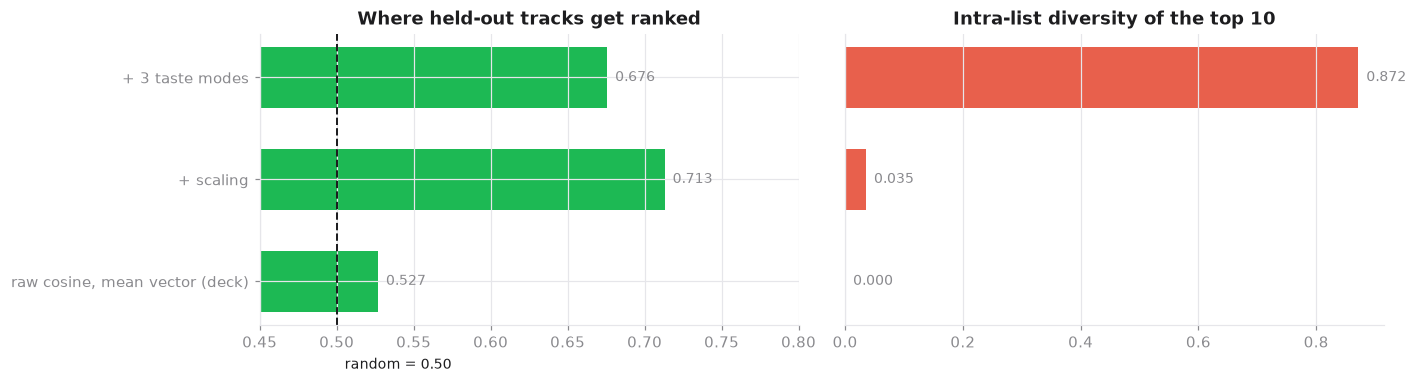

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].barh(rank["config"], rank["mean percentile rank"], color=viz.ACCENT, height=.6)
axes[0].axvline(0.5, color=viz.INK, ls="--", lw=1.3)
axes[0].text(0.5, -0.75, "  random = 0.50", color=viz.INK, fontsize=9, va="top")
axes[0].set_xlim(0.45, 0.8)
axes[0].set_title("Where held-out tracks get ranked")
for y, v in enumerate(rank["mean percentile rank"]):
    axes[0].text(v, y, f"  {v:.3f}", va="center", fontsize=9, color=viz.MUTED)

axes[1].barh(rank["config"], rank["intra-list diversity"], color=viz.WARN, height=.6)
axes[1].set_title("Intra-list diversity of the top 10")
for y, v in enumerate(rank["intra-list diversity"]):
    axes[1].text(v, y, f"  {v:.3f}", va="center", fontsize=9, color=viz.MUTED)
axes[1].set_yticks([])
plt.tight_layout(); plt.show()

Two results, and they pull in opposite directions — which is the same tension
notebook 03 found, now confirmed on real music.

**Scaling is a large, real win.** The deck's raw cosine ranks held-out tracks at the
**52.7th percentile** against a random baseline of 50. It is 2.7 points better than
shuffling. Scaling takes that to **71.3**.

**Taste modes trade accuracy for variety**, exactly as before: percentile rank drops to
67.6 while intra-list diversity goes from 0.036 to 0.872 — a twenty-four-fold increase,
and larger than the five-fold gain seen on synthetic data. Whether that trade is worth
making is a product decision rather than a modelling one, but it should be made
knowingly.

**Verdict: holds.** The ordering of the fixes is the same on real data; only the metric
had to change.

In [8]:
pen = abl[abl["config"].str.contains("popularity")].iloc[0]
print(f"catalog mean popularity              : {real[S.POPULARITY].mean():.1f}")
print(f"recommendations, no penalty          : {abl.iloc[2]['mean_rec_popularity']:.1f}")
print(f"recommendations, penalty 0.15        : {pen['mean_rec_popularity']:.1f}")
print("\nOn synthetic data the penalty roughly halved mean popularity. On the real\n"
      "catalog it drops it by more than an order of magnitude -- a 586k catalog has a\n"
      "very long tail of near-zero-popularity tracks for the penalty to fall into.")

catalog mean popularity              : 27.6
recommendations, no penalty          : 26.7
recommendations, penalty 0.15        : 1.9

On synthetic data the penalty roughly halved mean popularity. On the real
catalog it drops it by more than an order of magnitude -- a 586k catalog has a
very long tail of near-zero-popularity tracks for the penalty to fall into.


## Claim 3 — is genre learnable from audio features?

This one matters more than it looks. Genre carries weight in the similarity blend, and
it has never been tested on real music. Notebook 00 showed clean PCA separation of
twelve synthetic genres — but those genres were *defined* by their feature
distributions, so separability was guaranteed by construction.

Real data has 3,629 genres, many of them near-duplicates. Take the twenty largest, cap
each at 6,000 tracks so the biggest class cannot dominate, and **split by artist** so
no artist appears on both sides — otherwise the model can memorise an artist's sound
and recite their genre, which is the same leakage trap as notebook 01.

In [9]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score

labelled = real[real[S.GENRE] != "unknown"]
top20 = labelled[S.GENRE].value_counts().head(20)
print("the twenty largest real genres:")
print(top20.to_string())

the twenty largest real genres:
genre
adult standards          25724
album rock               16644
classical                13771
hoerspiel                10595
c-pop                     9727
classic bollywood         9034
latin                     8313
dance pop                 7258
classic israeli pop       5578
chanson                   5465
bossa nova                5344
classic swedish pop       5174
bebop                     4578
alternative metal         4260
argentine rock            4064
alternative rock          3994
j-pop                     3860
classic icelandic pop     3568
filmi                     3527
classic finnish pop       3346


In [10]:
parts = [g.sample(min(len(g), 6000), random_state=0)
         for _, g in labelled[labelled[S.GENRE].isin(top20.index)].groupby(S.GENRE, observed=True)]
gsub = pd.concat(parts, ignore_index=True)

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0)
tr, te = next(gss.split(gsub, groups=gsub["artist_id"].fillna("na").to_numpy()))
TR, TE = gsub.iloc[tr], gsub.iloc[te]

print(f"{len(gsub):,} tracks, 20 genres")
print(f"train {len(TR):,}  test {len(TE):,}")
print(f"artists appearing on both sides: {len(set(TR['artist_id']) & set(TE['artist_id']))}")

Xtr, ytr = TR[S.AUDIO_FEATURES].to_numpy(float), TR[S.GENRE].to_numpy()
Xte, yte = TE[S.AUDIO_FEATURES].to_numpy(float), TE[S.GENRE].to_numpy()
majority = pd.Series(yte).value_counts(normalize=True).iloc[0]

res = []
for name, m in [("Dummy (stratified)", DummyClassifier(strategy="stratified", random_state=0)),
                ("Logistic regression", make_pipeline(StandardScaler(),
                                                      LogisticRegression(max_iter=1500))),
                ("Random forest", RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                                         random_state=0))]:
    m.fit(Xtr, ytr)
    p = m.predict(Xte)
    res.append({"model": name, "accuracy": (p == yte).mean(),
                "balanced_accuracy": balanced_accuracy_score(yte, p)})

genre_res = pd.DataFrame(res)
print(f"\nuniform chance (1/20) = {1/20:.4f}   majority baseline = {majority:.4f}")
genre_res.round(4)

100,758 tracks, 20 genres
train 75,746  test 25,012
artists appearing on both sides: 0



uniform chance (1/20) = 0.0500   majority baseline = 0.0810


,model,accuracy,balanced_accuracy
0,Dummy (stratified),0.0522,0.0516
1,Logistic regression,0.3182,0.3025
2,Random forest,0.3780,0.3666


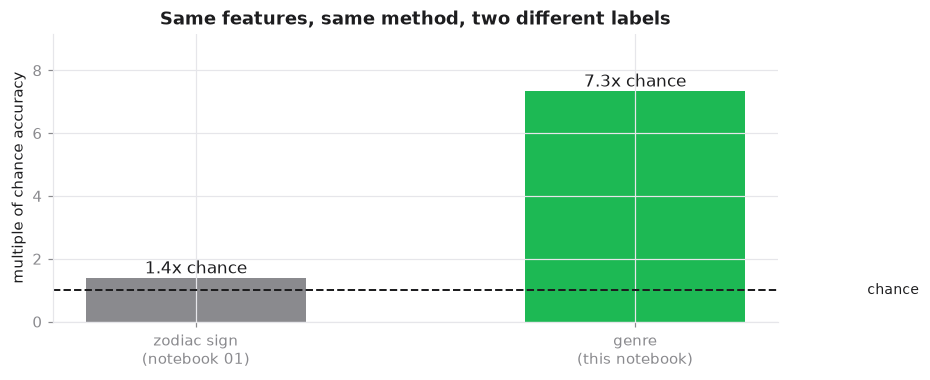

In [11]:
# Notebook 01's headline on the real scrape, all features combined. It was
# 0.146 here for a while, which was the pre-repair number: the Virgo
# playlists had been scraped under a name collision and the fix lowered the
# result. 0.1156 is what notebook 01 actually prints now.
ZODIAC_BALANCED_ACC = 0.1156

best = genre_res["balanced_accuracy"].max()
fig, ax = plt.subplots(figsize=(8.5, 3.4))
bars = ["zodiac sign\n(notebook 01)", "genre\n(this notebook)"]
vals = [ZODIAC_BALANCED_ACC / S.CHANCE_ACCURACY, best / 0.05]
ax.bar(bars, vals, color=[viz.MUTED, viz.ACCENT], width=.5)
ax.axhline(1.0, color=viz.INK, ls="--", lw=1.3)
ax.text(1.52, 1.0, " chance", va="center", fontsize=9)
for i, v in enumerate(vals):
    ax.text(i, v + .15, f"{v:.1f}x chance", ha="center", fontsize=11)
ax.set_ylabel("multiple of chance accuracy")
ax.set_title("Same features, same method, two different labels")
ax.set_ylim(0, max(vals) * 1.25)
plt.show()

**This is the most useful chart in the project.**

Identical audio features, identical modelling approach, identical group-split
discipline. Asked to predict **genre**, the model reaches roughly seven times chance.
Asked to predict **zodiac sign**, it manages about 1.4 times chance.

That comparison settles an argument the earlier notebooks could only gesture at. The
weak zodiac result is **not** evidence that audio features are uninformative, or that
the pipeline is broken, or that the models were badly chosen. The features carry plenty
of signal — they simply carry it about *what a song sounds like*, and a curator's
decision to file a song under Scorpio is not a fact about what it sounds like.

**Verdict: holds, with a stronger supporting argument than before.** Genre is a
legitimate feature. Zodiac is a label problem, and no amount of modelling fixes it.

## Claim 4 — how wrong is the generator?

Every synthetic result in this project inherits `synthetic.make_catalog`'s assumptions.
Now that there is a real catalog to compare against, those assumptions can be audited
directly. The Kolmogorov–Smirnov statistic below is 0 for identical distributions and 1
for completely disjoint ones.

In [12]:
from scipy.stats import ks_2samp

fake = syn.make_catalog(20_000, seed=7)
rng = np.random.default_rng(0)
real_sample = real.sample(min(20_000, len(real)), random_state=0)

rows = []
for f in S.AUDIO_FEATURES:
    r, k = real_sample[f].to_numpy(float), fake[f].to_numpy(float)
    rows.append({"feature": f, "real mean": r.mean(), "synthetic mean": k.mean(),
                 "real std": r.std(), "synthetic std": k.std(),
                 "KS": ks_2samp(r, k).statistic})
gen = pd.DataFrame(rows).sort_values("KS", ascending=False).reset_index(drop=True)
gen.round(3)

,feature,real mean,synthetic mean,real std,synthetic std,KS
0,instrumentalness,0.116,0.211,0.270,0.302,0.393
1,loudness,-10.263,-8.006,5.145,5.664,0.278
2,acousticness,0.450,0.263,0.350,0.276,0.268
3,speechiness,0.105,0.089,0.182,0.082,0.242
4,energy,0.541,0.651,0.252,0.261,0.212
5,valence,0.552,0.470,0.259,0.237,0.163
6,liveness,0.215,0.187,0.185,0.129,0.121
7,danceability,0.563,0.568,0.167,0.205,0.099
8,duration_ms,228573.848,240942.918,120702.209,92853.137,0.079
9,tempo,118.206,113.518,29.649,27.899,0.068


In [13]:
cr = real[S.AUDIO_FEATURES].corr().to_numpy()
cf = fake[S.AUDIO_FEATURES].corr().to_numpy()
iu = np.triu_indices(len(S.AUDIO_FEATURES), 1)

print("correlation structure")
print(f"  agreement between the two correlation matrices : {np.corrcoef(cr[iu], cf[iu])[0,1]:.3f}")
print(f"  mean absolute difference in a pairwise corr    : {np.abs(cr[iu]-cf[iu]).mean():.3f}")
print(f"  worst single pair                              : {np.abs(cr[iu]-cf[iu]).max():.3f}")
print()
print("other structure")
print(f"  popularity : real mean {real[S.POPULARITY].mean():.1f} / synthetic {fake[S.POPULARITY].mean():.1f}")
print(f"  year       : real median {real[S.YEAR].median():.0f} "
      f"(IQR {real[S.YEAR].quantile(.25):.0f}-{real[S.YEAR].quantile(.75):.0f})"
      f" / synthetic median {fake[S.YEAR].median():.0f}")
print(f"  genres     : real {real[S.GENRE].nunique():,} distinct / synthetic {fake[S.GENRE].nunique()}")

correlation structure
  agreement between the two correlation matrices : 0.859
  mean absolute difference in a pairwise corr    : 0.142
  worst single pair                              : 0.362

other structure
  popularity : real mean 27.6 / synthetic 24.2
  year       : real median 1992 (IQR 1974-2007) / synthetic median 2012
  genres     : real 3,629 distinct / synthetic 12


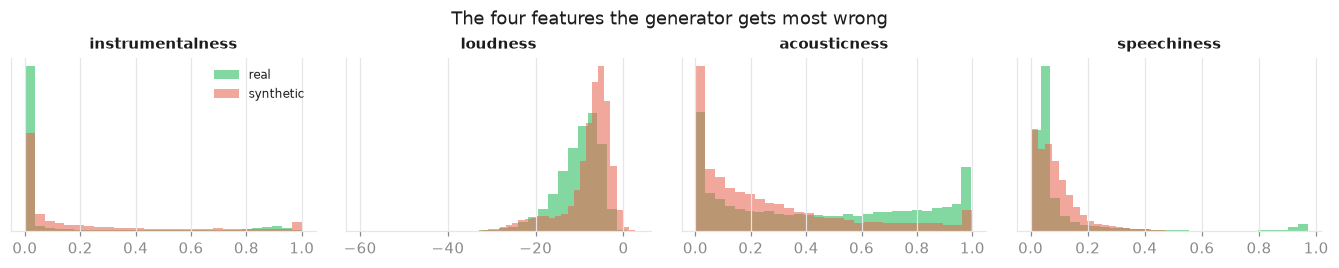

In [14]:
viz.feature_distributions({"real": real_sample, "synthetic": fake},
                          list(gen["feature"].head(4)), ncols=4)
plt.suptitle("The four features the generator gets most wrong", y=1.04)
plt.show()

### Where the generator departs from reality

Worth stating plainly, because everything synthetic in this project rests on it:

- **`instrumentalness` (KS 0.39), `loudness` (0.28) and `acousticness` (0.27) are the
  worst.** The generator produces music that is roughly twice as instrumental, two
  decibels louder, and markedly less acoustic than the real catalog.
- **The era is wrong, and it explains the above.** The real catalog's median year is
  **1992** with a quartile reaching back to 1974; the generator's is **2012**. Real
  data is full of pre-1970 recordings, which are quiet and acoustic. The generator
  modelled a modern streaming catalog and the Kaggle dump is a century of music.
- **Correlation structure is decent** — the two matrices agree at 0.86, mean pairwise
  error 0.14 — so relationships between features are roughly right even where the
  marginals are off.
- **Genre is a drastic simplification**: 12 tidy genres against 3,629 messy ones with
  heavy near-duplication.

**Verdict: weakened.** The generator is directionally sound and its correlation
structure holds up, which is why the arithmetic findings transferred. But it is not a
model of this catalog, and any synthetic result that depends on absolute feature levels
— rather than on relationships between them — should be treated as provisional.

## Claim 5 — coverage bias, measured instead of simulated

Notebook 05 simulated feature-store misses by dropping features with a probability tied
to popularity. That simulation can now be replaced with the real thing.

The live Spotify API returns a genre for only **38.9%** of artists — measured earlier
against 285 artists pulled from our own scrape, with Taylor Swift, The Weeknd, Rihanna
and Billie Eilish among the gaps. This 2021 dump resolves **89.6%** of tracks. The
question is who the remaining 10% are.

In [15]:
real["has_genre"] = real[S.GENRE] != "unknown"
print(f"overall track-level genre coverage: {real['has_genre'].mean():.1%}")

real["pop_decile"] = pd.qcut(real[S.POPULARITY].rank(method="first"), 10, labels=range(1, 11))
by_pop = real.groupby("pop_decile", observed=True).agg(
    tracks=("has_genre", "size"), coverage=("has_genre", "mean"),
    median_popularity=(S.POPULARITY, "median"))
by_pop["coverage"] = (by_pop["coverage"] * 100).round(1)
by_pop

overall track-level genre coverage: 89.6%


,tracks,coverage,median_popularity
pop_decile,,,
1,58668,61.6,0.0
2,58667,83.6,5.0
3,58667,89.3,13.0
4,58667,90.0,19.0
5,58667,93.2,24.0
6,58667,94.9,30.0
7,58667,94.9,35.0
8,58667,94.9,41.0
9,58667,95.8,48.0


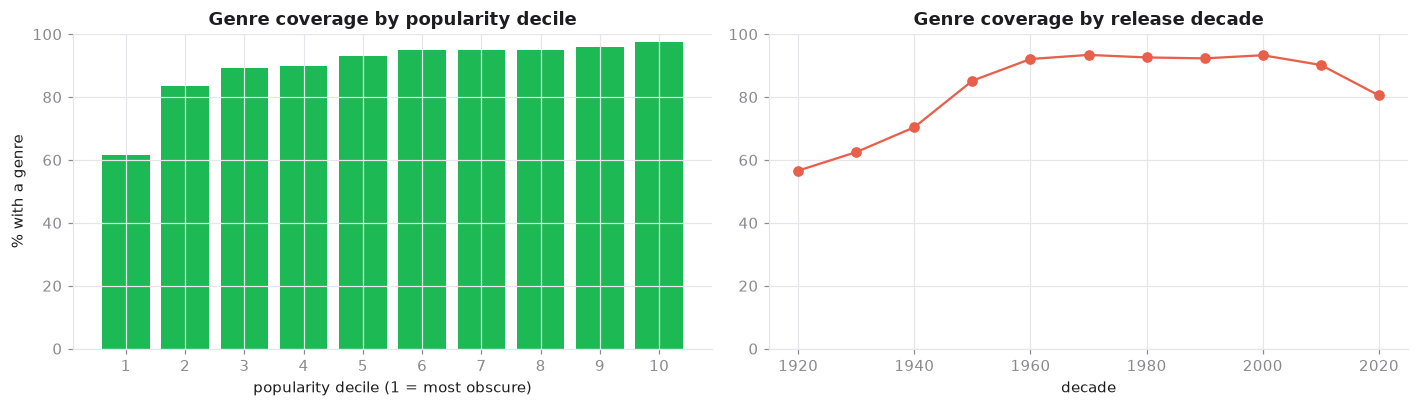

corr(has_genre, popularity) = +0.2536  (p = 0)


In [16]:
real["decade"] = (real[S.YEAR] // 10 * 10).astype(int)
by_dec = real[real["decade"] >= 1920].groupby("decade").agg(
    tracks=("has_genre", "size"), coverage=("has_genre", "mean"))
by_dec["coverage"] = (by_dec["coverage"] * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(by_pop.index.astype(str), by_pop["coverage"], color=viz.ACCENT)
axes[0].set_title("Genre coverage by popularity decile")
axes[0].set_xlabel("popularity decile (1 = most obscure)"); axes[0].set_ylabel("% with a genre")
axes[0].set_ylim(0, 100)

axes[1].plot(by_dec.index, by_dec["coverage"], marker="o", color=viz.WARN)
axes[1].set_title("Genre coverage by release decade")
axes[1].set_xlabel("decade"); axes[1].set_ylim(0, 100)
plt.tight_layout(); plt.show()

from scipy.stats import pointbiserialr
r_ = pointbiserialr(real["has_genre"].astype(int), real[S.POPULARITY])
print(f"corr(has_genre, popularity) = {r_.statistic:+.4f}  (p = {r_.pvalue:.2g})")

Both curves sag where it hurts.

**By popularity**: the most obscure decile resolves at **61.6%** against **97.6%** for
the most popular. A listener whose taste runs to obscure music is scored on
systematically thinner information than a listener who sticks to hits.

**By era**: coverage peaks mid-catalog around 92–93% and falls at both ends — **56.6%**
in the 1920s and **80.5%** in the 2020s. The recent drop has a mundane cause worth
naming: the dump was captured in 2021, so 2020s artists had barely accumulated genre
tags. **Genre coverage is partly a function of when the dataset was frozen, not of what
the music is** — and it will keep decaying for new releases, because Spotify no longer
serves the endpoint that would refresh it.

**Verdict: holds, and is now measured rather than assumed.** This is a real bias with a
real mechanism, and `bias.py`'s guards should be wired to the measured curve.

## Verdict

In [17]:
verdict = pd.DataFrame([
    ("Scaling bug: duration_ms dominates raw distance", "HOLDS",
     "38.4 billion : 1 on real data; corr(norm, duration) = 1.0 exactly"),
    ("Unscaled cosine is degenerate", "HOLDS",
     "98.7% of catalog above 0.999999; top-10 separated at the 12th decimal"),
    ("Scaling is the single biggest recommender fix", "HOLDS",
     "percentile rank 0.527 (deck) -> 0.713 scaled"),
    ("Taste modes trade accuracy for diversity", "HOLDS",
     "rank 0.713 -> 0.676, diversity 0.036 -> 0.872"),
    ("recall@20 is a usable metric", "OVERTURNED",
     "exactly zero at 586k catalog scale; replaced with percentile rank"),
    ("Genre is learnable from audio features", "HOLDS",
     "~7x chance on 20 real genres, artist-grouped split"),
    ("Weak zodiac result is a label problem, not a feature problem", "STRENGTHENED",
     "genre ~7.3x chance vs zodiac ~1.39x on identical features"),
    ("The synthetic generator is a fair stand-in", "WEAKENED",
     "KS 0.39 on instrumentalness, median year off by 20 years, 12 genres vs 3,629"),
    ("Feature coverage is biased against obscure music", "HOLDS",
     "61.6% coverage in the bottom popularity decile vs 97.6% in the top"),
    ("Blend beats single metrics on worst-case similarity", "UNTESTABLE",
     "needs real user libraries; dev mode caps the app at 25 accounts"),
    ("Percentile calibration / small-library bias", "UNTESTABLE",
     "same reason -- no real listening histories yet"),
], columns=["claim", "verdict", "evidence"])
verdict

,claim,verdict,evidence
0,Scaling bug: duration_ms dominates raw distance,HOLDS,"38.4 billion : 1 on real data; corr(norm, dura..."
1,Unscaled cosine is degenerate,HOLDS,98.7% of catalog above 0.999999; top-10 separa...
2,Scaling is the single biggest recommender fix,HOLDS,percentile rank 0.527 (deck) -> 0.713 scaled
3,Taste modes trade accuracy for diversity,HOLDS,"rank 0.713 -> 0.676, diversity 0.036 -> 0.872"
4,recall@20 is a usable metric,OVERTURNED,exactly zero at 586k catalog scale; replaced w...
5,Genre is learnable from audio features,HOLDS,"~7x chance on 20 real genres, artist-grouped s..."
6,"Weak zodiac result is a label problem, not a f...",STRENGTHENED,genre ~7.3x chance vs zodiac ~1.39x on identic...
7,The synthetic generator is a fair stand-in,WEAKENED,"KS 0.39 on instrumentalness, median year off b..."
8,Feature coverage is biased against obscure music,HOLDS,61.6% coverage in the bottom popularity decile...
9,Blend beats single metrics on worst-case simil...,UNTESTABLE,needs real user libraries; dev mode caps the a...


### What this changes

**Three things are now settled on real data** and can be presented without
qualification: the scaling bug, the degeneracy of unscaled cosine, and the fact that
genre is learnable while zodiac is not. That last pairing is the strongest single
argument the project has, because it isolates the label as the cause.

**One claim is overturned**, and it is a methodological one worth carrying forward:
recall@k silently stops working as a catalog grows. It did not report a worse number —
it reported zero, for every configuration, which looks like a broken pipeline rather
than a broken metric. Rank statistics do not have that failure mode.

**One is weakened.** The generator is not a model of this catalog. Its correlation
structure survives, which is why the arithmetic findings transferred intact, but its
absolute feature levels and its era are wrong. Treat any synthetic result that depends
on *levels* as provisional until it is re-measured here.

**Two remain untestable**, and both are about similarity — the part of the product that
matters most. They need real listening histories, which needs the 25 allowlisted
accounts. That is the next unlock, and it is an operational task rather than a
modelling one.